# **Inicio de carga y contexto**

## Cargando el data set

In [59]:
# Importamos las librerias necesarias.
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt



In [60]:
#Cargo data set bajo variable de nombre pd
df=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Trabajo final/Data Set/CO2 Emissions.csv')

## Contexto del tópico elegido

El cambio climático es una problemática ambiental de escala global que afecta a nuestra calidad de vida. Dentro de los gases de efecto invernadero responsables del calentamiento global, el dióxido de carbono es uno de los más significativos, y sus emisiones están estrechamente ligadas a la actividad humana, en especial al transporte, la generación de energía y los procesos industriales.

En este contexto, el transporte representa una de las fuentes más importantes de emisión de dióxido de carbono. Se analizará esta problemática, a partir de un data set centrado específicamente en las emisiones de CO2 generadas por vehículos en Canadá, abarcando datos publicados por el gobierno canadiense entre los años 2014 y 2020.

Analizar este data set permitirá comprender cómo las características técnicas de los vehículos inciden en su impacto ambiental. También, buscará identificar patrones y tendencias que podrían ser fundamentales para el desarrollo de estrategias de movilidad sostenible.

## **Diccionario**





*   **Make:** marca del vehículo.
*   **Model:** modelo
*   **Vehicle Class:** categoría del vehículo según tamaño y tipo.
*   **Engine Size (L):** tamaño del motor en litros
*   **Cylinders:** Número de cilindros del motor.
*  **Transmission:** Tipo de transmisión (automática o manual.
*   **Fuel Type:** Tipo de combustible utilizado.
*   **Fuel Consumption City (L/100 km):** Consumo de combustible en ciudad (litros cada 100 km).
*   **Fuel Consumption Hwy (L/100 km):** Consumo de combustible en autopista (litros cada 100 km).
*   **Fuel Consumption Comb (L/100 km):** Consumo de combustible combinado (litros cada 100 km).
*   **Fuel Consumption Comb (mpg):** Consumo de combustible combinado (millas por galón).
*   **CO2 Emissions(g/km):** Emisiones de dióxido de carbono (gramos por kilómetro recorrido)













# **Exploración y visualización**

## **Exploración inicial**

In [61]:
#Lectura de datos iniciales
df.head(10)


,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
5,ACURA,RLX,MID-SIZE,3.5,6,AS6,Z,11.9,7.7,10.0,28,230
6,ACURA,TL,MID-SIZE,3.5,6,AS6,Z,11.8,8.1,10.1,28,232
7,ACURA,TL AWD,MID-SIZE,3.7,6,AS6,Z,12.8,9.0,11.1,25,255
8,ACURA,TL AWD,MID-SIZE,3.7,6,M6,Z,13.4,9.5,11.6,24,267
9,ACURA,TSX,COMPACT,2.4,4,AS5,Z,10.6,7.5,9.2,31,212


In [62]:
#Observamos el número de columnas y filas
df.shape

(7385, 12)

In [63]:
#Resumen del data frame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              7385 non-null   object 
 1   Model                             7385 non-null   object 
 2   Vehicle Class                     7385 non-null   object 
 3   Engine Size(L)                    7385 non-null   float64
 4   Cylinders                         7385 non-null   int64  
 5   Transmission                      7385 non-null   object 
 6   Fuel Type                         7385 non-null   object 
 7   Fuel Consumption City (L/100 km)  7385 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   7385 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  7385 non-null   float64
 10  Fuel Consumption Comb (mpg)       7385 non-null   int64  
 11  CO2 Emissions(g/km)               7385 non-null   int64  
dtypes: flo

El Data Frame tiene en total 7385 filas y 12 columnas, no posee valores faltantes en ninguna columna, con lo cuál no hará falta imputar ni eliminar datos por este motivo. Hay diferentes tipos de datos:
*   Categóricos (tipo object): Make, Model, Vehicle Class, Transmission, Fuel Type.
*   Numéricas enteras (int64): Cylinders, Fuel Consumption Comb (mpg), CO2 Emissions (g/km).
*   Numéricas decimales (float64): Engini size (L), Fuel Consumption City, Fuel Consumption Hwy y Fuel Consumption Comb.



# **Limpieza de datos**

In [64]:
# Verifico existencia de datos duplicados
print("Duplicados exactos:", df.duplicated().sum())

Duplicados exactos: 1103


In [65]:
#Observo que filas tienen duplicados exactos
df[df.duplicated(keep=False)]

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
5,ACURA,RLX,MID-SIZE,3.5,6,AS6,Z,11.9,7.7,10.0,28,230
12,ALFA ROMEO,4C,TWO-SEATER,1.8,4,AM6,Z,9.7,6.9,8.4,34,193
13,ASTON MARTIN,DB9,MINICOMPACT,5.9,12,A6,Z,18.0,12.6,15.6,18,359
15,ASTON MARTIN,V8 VANTAGE,TWO-SEATER,4.7,8,AM7,Z,17.4,11.3,14.7,19,338
...,...,...,...,...,...,...,...,...,...,...,...,...
7356,TOYOTA,Tundra,PICKUP TRUCK - STANDARD,5.7,8,AS6,X,17.7,13.6,15.9,18,371
7365,VOLKSWAGEN,Golf GTI,COMPACT,2.0,4,M6,X,9.8,7.3,8.7,32,203
7366,VOLKSWAGEN,Jetta,COMPACT,1.4,4,AS8,X,7.8,5.9,7.0,40,162
7367,VOLKSWAGEN,Jetta,COMPACT,1.4,4,M6,X,7.9,5.9,7.0,40,163


In [66]:
# Eliminar filas duplicadas
df.drop_duplicates(inplace=True)

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6282 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              6282 non-null   object 
 1   Model                             6282 non-null   object 
 2   Vehicle Class                     6282 non-null   object 
 3   Engine Size(L)                    6282 non-null   float64
 4   Cylinders                         6282 non-null   int64  
 5   Transmission                      6282 non-null   object 
 6   Fuel Type                         6282 non-null   object 
 7   Fuel Consumption City (L/100 km)  6282 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   6282 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  6282 non-null   float64
 10  Fuel Consumption Comb (mpg)       6282 non-null   int64  
 11  CO2 Emissions(g/km)               6282 non-null   int64  
dtypes: float64(

Se eliminaron las filas idénticas para mejorar la calidad del conjunto de datos y evitar distorsionar los resultados.

In [68]:
#Lista de columnas numéricas
columnas_numéricas = ['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)', 'Fuel Consumption Comb (mpg)', 'CO2 Emissions(g/km)']

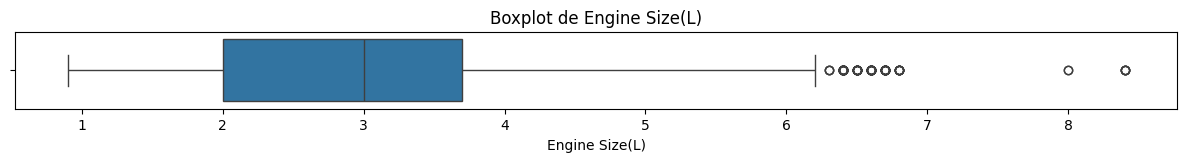

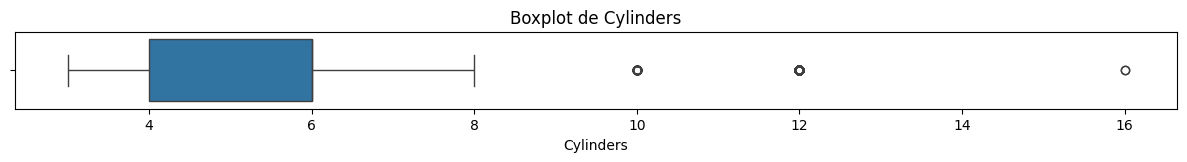

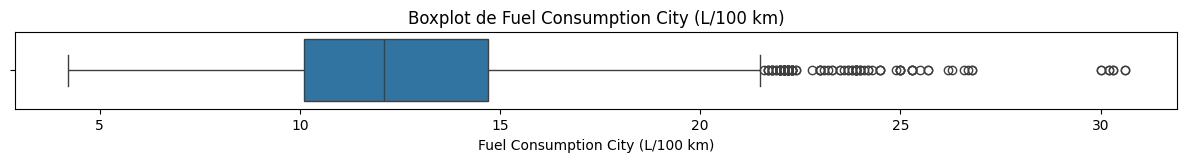

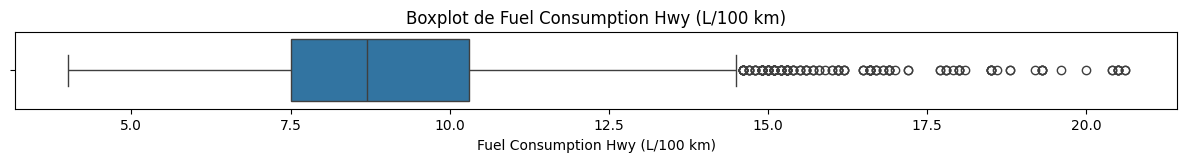

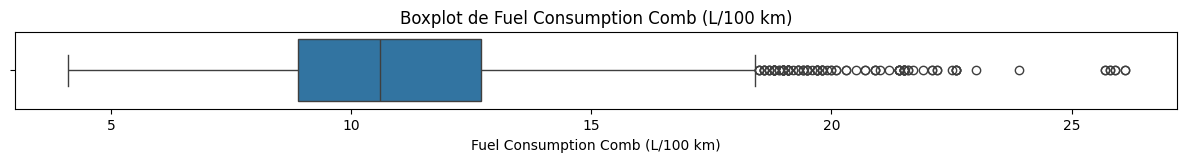

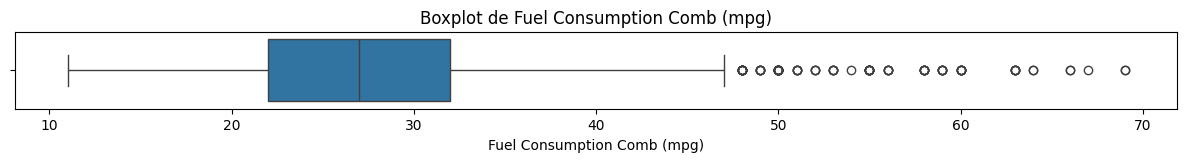

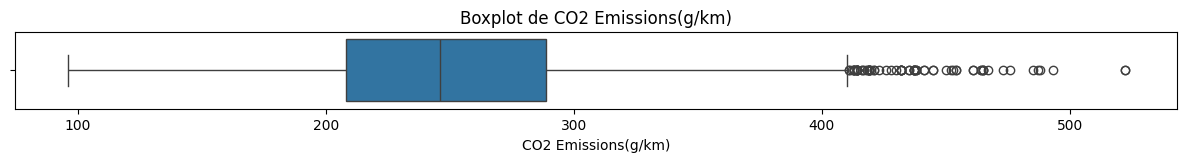

In [69]:
#Visualización de outliers de las variables numéricas con boxplots
for col in columnas_numéricas:
    plt.figure(figsize=(15, 1))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot de {col}')
    plt.show()


In [70]:
# Detección de outliers por IQR
outlier_stats = {}
for col in columnas_numéricas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

# Límites
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

# Identificación de outliers
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    cantidad = outliers.shape[0]
    porcentaje = round(cantidad / len(df) * 100, 2)

# Guardo resultados
    outlier_stats[col] = {'Cantidad de outliers': cantidad,'Porcentaje (%)': porcentaje,
                          'Límite inferior': lower_bound,
                          'Límite superior': upper_bound}

In [71]:
# Mostrar los resultados en un DataFrame
outlier_df = pd.DataFrame(outlier_stats).T
outlier_df

,Cantidad de outliers,Porcentaje (%),Límite inferior,Límite superior
Engine Size(L),121.0,1.93,-0.55,6.25
Cylinders,177.0,2.82,1.00,9.00
Fuel Consumption City (L/100 km),116.0,1.85,3.20,21.60
Fuel Consumption Hwy (L/100 km),150.0,2.39,3.30,14.50
Fuel Consumption Comb (L/100 km),115.0,1.83,3.20,18.40
Fuel Consumption Comb (mpg),95.0,1.51,7.00,47.00
CO2 Emissions(g/km),74.0,1.18,86.50,410.50


Los valores atípicos (outliers) detectados en todas las variables numéricas, representan una pequeña parte de la totalidad de los datos (1% - 2,8%), por ello, decido mantenerlos ya que, considero que no representan inconsistencias.

Si observo los valores máximos y mínimos para cada variable por separado, puedo decir que los outliers no representan errores de carga ni inconsistencias. Al contrario, corresponden a vehículos menos comunes, pero existentes dentro del parque automotor canadiense: autos deportivos, SUV, pickups para uso industrial, y modelos con muy baja eficiencia energética. En lugar de distorsionar el análisis, estos registros reflejan una representación más completa del espectro de emisiones y consumo reales. Por ello, decido conservar todos los outliers en el conjunto de datos.


# **Análisis estadístico**



## **Variables categóricas**

In [72]:
#Lista de columnas categóricas
columnas_categoricas = ['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel Type']


### **Exploración numérica**

In [73]:
#Realizo exploración numérica
for col in columnas_categoricas:
    print(f"Variable: {col}")
    print(f"Cantidad de valores únicos: {df[col].nunique()}")
    print("Valores más frecuentes:")
    print(df[col].value_counts().head(10))
    print("-" * 50)

Variable: Make
Cantidad de valores únicos: 42
Valores más frecuentes:
Make
FORD             577
CHEVROLET        515
BMW              501
MERCEDES-BENZ    365
PORSCHE          296
GMC              289
TOYOTA           276
AUDI             263
NISSAN           213
JEEP             200
Name: count, dtype: int64
--------------------------------------------------
Variable: Model
Cantidad de valores únicos: 2053
Valores más frecuentes:
Model
F-150 FFV        32
F-150 FFV 4X4    31
MUSTANG          27
FOCUS FFV        24
F-150 4X4        20
F-150            19
SONIC 5          18
ATS              18
COMPASS          18
JETTA            18
Name: count, dtype: int64
--------------------------------------------------
Variable: Vehicle Class
Cantidad de valores únicos: 16
Valores más frecuentes:
Vehicle Class
SUV - SMALL                1006
MID-SIZE                    983
COMPACT                     903
SUV - STANDARD              613
SUBCOMPACT                  533
FULL-SIZE                   5

Al explorar las variables categóricas del data set, se identifican las siguientes características:

*   **Fabricante (Make):** se encontraron 42 marcas de vehículos diferentes, siendo Ford y Chevrolet las más frecuentes.
*  **Modelo (Model):** aquí se observa una gran cantidad de valores únicos. Dada la baja frecuencia individual de la mayoría de ellos, no es una variable adecuada para un análisis directo, su utilidad se centra más en exploraciones detalladas de modelos específicos.
*   **Categoría de vehículo (Vehicle Class):** son 16 las categorías bien definidas, es una variable excelente para realizar análisis comparativos y obtener insights sobre las emisiones entre diferentes segmentos de vehículos.
*   **Tipo de transmisión (Transmission):** se identificaron 27 tipos de transmisiones diferentes, lo que proporciona un nivel de detalle interesante para entender su influencia en las emisiones.
*   **Tipo de combustible (Fuel Type):** Se observa predominancia del combustible regular (X) y premium (Z). Por otro lado, los vehículos que utilizan electricidad (N) están prácticamente ausentes, con un único caso registrado, lo que limita su análisis en este caso.







### **Exploración visual**

*Cantidad de vehículos vs. tipo de combustible*

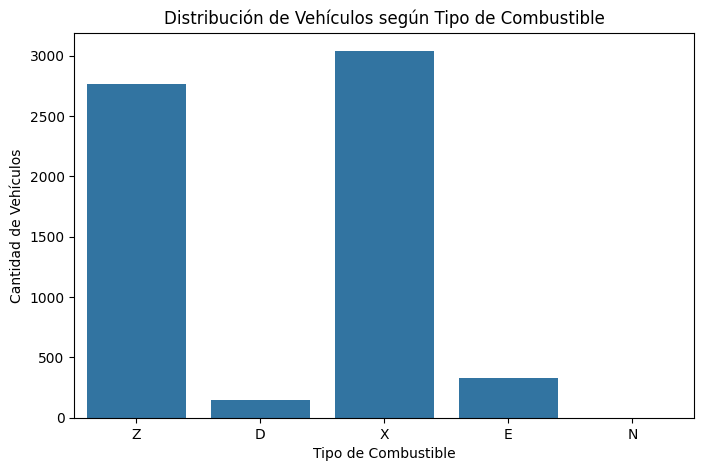

In [74]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Fuel Type', data=df)
plt.title('Distribución de Vehículos según Tipo de Combustible')
plt.xlabel('Tipo de Combustible')
plt.ylabel('Cantidad de Vehículos')
plt.show()

Confirmando lo observado en el análisis numérico, el data set releva una gran dependencia de la nafta regular (X) y la premium (Z) como combustibles principales. Las opciones de diésel (D) y etanol (E) representan una fracción significativamente menor.
Los vehículos eléctricos (N), presentan un sólo registro. Esta marcada ausencia indica una adopción incipiente o casi nula de tecnologías de cero emisiones en el sector automotriz canadiense en el período de estudio.

*Marca vs. tipo de combustible*

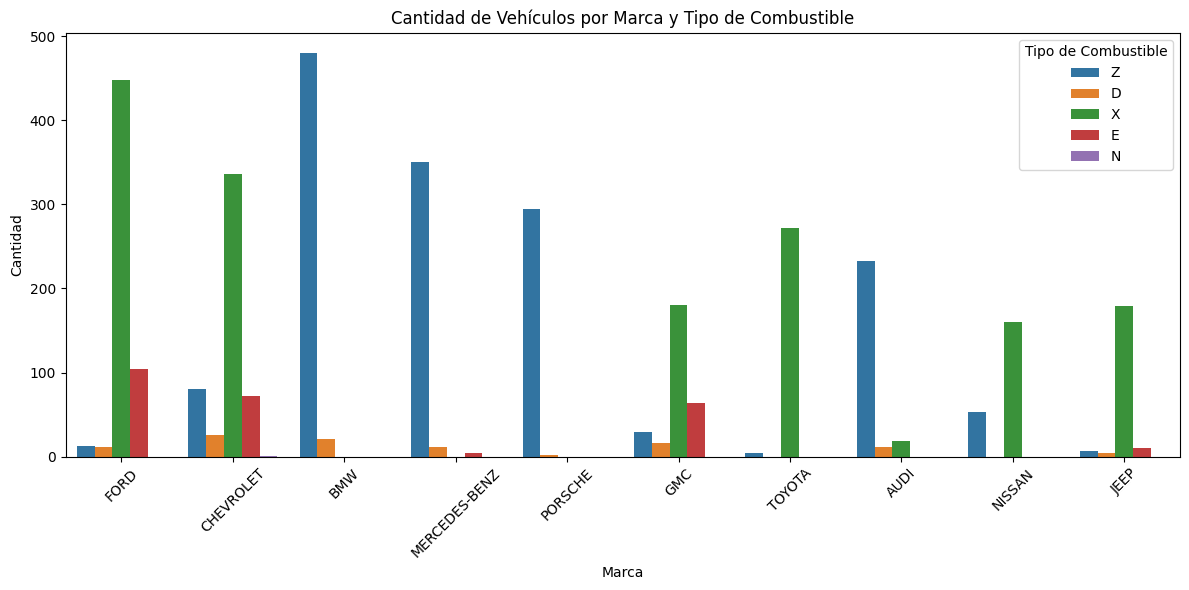

In [75]:
plt.figure(figsize=(12, 6))
sns.countplot(x='Make', hue='Fuel Type', data=df, order=df['Make'].value_counts().index[:10])
plt.title('Cantidad de Vehículos por Marca y Tipo de Combustible')
plt.xlabel('Marca')
plt.ylabel('Cantidad')
plt.xticks(rotation=45)
plt.legend(title='Tipo de Combustible')
plt.tight_layout()
plt.show()

Entre las marcas más populares (Ford, Chevrolet, BMW), se observa que la mayoría de sus modelos utilizan nafta y en preferencia regular (X). Ford y Chevrolet presentan más variedad en el tipo de combustible. No se observa evidencia en este conjunto de datos que alguna marca esté impulsando significativamente los vehículos eléctricos.

*Cantidad de vehículos vs. categoría.*

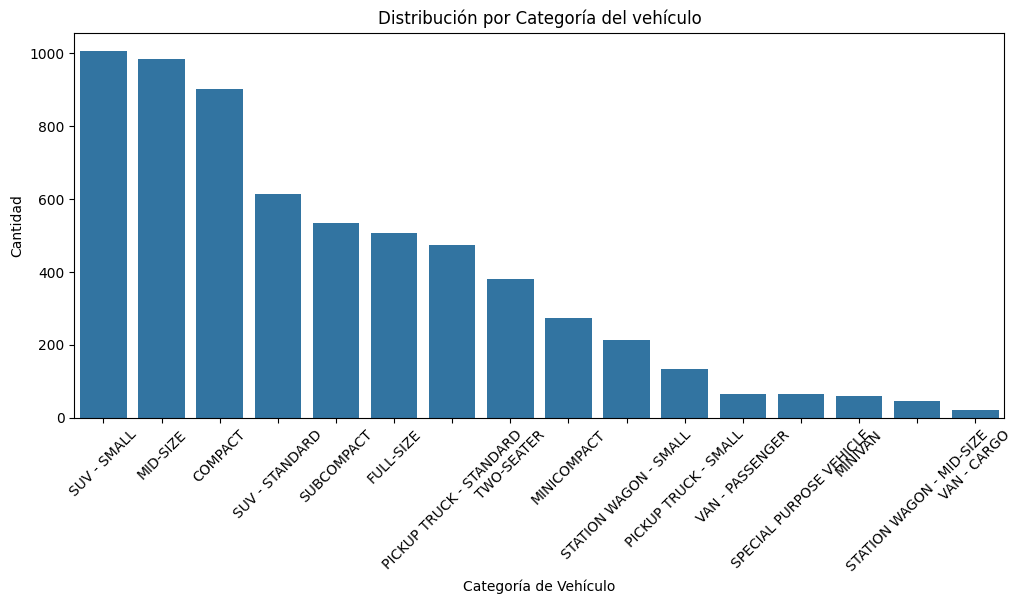

In [76]:
plt.figure(figsize=(12, 5))
sns.countplot(x='Vehicle Class', data=df, order=df['Vehicle Class'].value_counts().index)
plt.title('Distribución por Categoría del vehículo')
plt.xlabel('Categoría de Vehículo')
plt.ylabel('Cantidad')
plt.xticks(rotation=45)
plt.show()

Las categorías de vehículos más representadas son SUV pequeños, vehículos medianos y compactos, lo que refleja una tendencia en la industria automotriz hacia este tipo de carrocerías. Las categorías como two-seater (biplaza) o station wagon (rural o familiar) son mucho menos comunes en el mercado estudiado.

## **Variables numéricas**

### **Exploración numérica**

In [77]:
#Lista de columnas numéricas
columnas_numéricas = ['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)', 'Fuel Consumption Comb (mpg)', 'CO2 Emissions(g/km)']

In [78]:
#Resumen estadístico de los datos numéricos
df.describe()

,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
count,6282.000000,6282.000000,6282.000000,6282.000000,6282.000000,6282.000000,6282.000000
mean,3.161812,5.618911,12.610220,9.070583,11.017876,27.411016,251.157752
std,1.365201,1.846250,3.553066,2.278884,2.946876,7.245318,59.290426
min,0.900000,3.000000,4.200000,4.000000,4.100000,11.000000,96.000000
25%,2.000000,4.000000,10.100000,7.500000,8.900000,22.000000,208.000000
50%,3.000000,6.000000,12.100000,8.700000,10.600000,27.000000,246.000000
75%,3.700000,6.000000,14.700000,10.300000,12.700000,32.000000,289.000000
max,8.400000,16.000000,30.600000,20.600000,26.100000,69.000000,522.000000


**Análisis de la tabla:**


*   **Tamaño del motor.** El tamaño del motor presenta una media de 3,16 L y una mediana de 3,0 L. La cercanía de estos dos valores es un indicador de una distribución relativamente simétrica, lo que sugiere que los datos no están fuertemente sesgados hacia un extremo particular. Por otro lado, la desviación estándar de 1,37 L revela una considerable variabilidad en el tamaño de los motores. Este rango se extiende desde unidades muy pequeñas de 0,9 L hasta motores potentes de 8,4 L. Esta amplia dispersión es importante, ya que evita la falsa impresión de que la mayoría de los motores se agrupan estrechamente alrededor del promedio.
* **Número de cilindros.** Para el número de cilindros, la mediana es de 6,0, lo que indica que la mitad de los vehículos posee 6 cilindros o menos. Por otro lado, la media es ligeramente inferior, de 5,62 cilindros. Esta pequeña diferencia entre la media y la mediana podría sugerir una ligera asimetría negativa (sesgo a la izquierda), insinuando que hay un mayor número de vehículos con menos de 6 cilindros. Además, la desviación estándar de 1,85 revela una amplia variedad de cilindradas, que van desde los 3 hasta los 16 cilindros. Esto subraya la heterogeneidad del parque automotor representado en los datos.
*  **Consumo de combustible.** Observo patrones claros en sus diferentes escenarios:

  -	***En Ciudad:*** Como es de esperar, el consumo promedio es más elevado, situándose en 12,61 L/100km. Este valor es ligeramente superior a la mediana, lo que indica una asimetría positiva (sesgo a la derecha). Esto sugiere la existencia de vehículos con consumos notablemente altos que influyen en el promedio general. La desviación estándar de 3,55 L/100km es considerable, revelando una amplia variabilidad en la eficiencia del consumo en entornos urbanos, con un rango que va desde vehículos muy económicos (4,2 L/100km) hasta otros que demandan una gran cantidad de combustible (hasta 30,6 L/100km).

  - ***En Ruta:*** El consumo es significativamente menor, con una media de 9,07 L/100km. Similar al consumo en ciudad, esta media es un poco más alta que la mediana (8,7 L/100km), lo que también indica que algunos vehículos de alto consumo en ruta impactan el promedio. La desviación estándar de 2.28 L/100km, aunque menor que en ciudad, sigue siendo significativa. Esto demuestra que, incluso en condiciones de ruta, hay una considerable diversidad en la eficiencia de los vehículos (desde 4,0 L/100km hasta 20,6 L/100km).

  - ***Consumo Combinado:*** Esta métrica es útil para evaluar la eficiencia general del vehículo. La media se sitúa en 11,02 L/100km, siendo ligeramente mayor que la mediana (10,6 L/100km). Esto sugiere una leve asimetría hacia valores de alto consumo. La desviación estándar de 2,95 L/100km es alta, lo que destaca la gran variabilidad general en la eficiencia de combustible de la flota. Esto significa que la eficiencia varía ampliamente entre los vehículos, desde los más ahorradores (mínimo de 4,10 L/100km) hasta los que más combustible demandan (máximo de 26,10 L/100km).

* **Emisiones de CO2.** Las emisiones de CO2 muestran un promedio de 251.16 g/km, mientras que el valor central (mediana) se sitúa en torno a los 246 g/km. Esta diferencia sugiere la presencia de vehículos con emisiones particularmente altas, que desplazan el promedio al alza. Además, la desviación estándar de 59.29 g/km revela una amplia disparidad en los niveles de emisión entre los vehículos. Los datos varían significativamente, desde un mínimo de 96 g/km hasta un máximo de 522 g/km. Esta considerable variabilidad subraya que, aunque existen vehículos con emisiones relativamente bajas en la flota, una parte significativa de los vehículos contribuye con niveles muy elevados de CO2.



### **Exploración visual**

***Análisis Univariable***

<Axes: xlabel='CO2 Emissions(g/km)', ylabel='Count'>

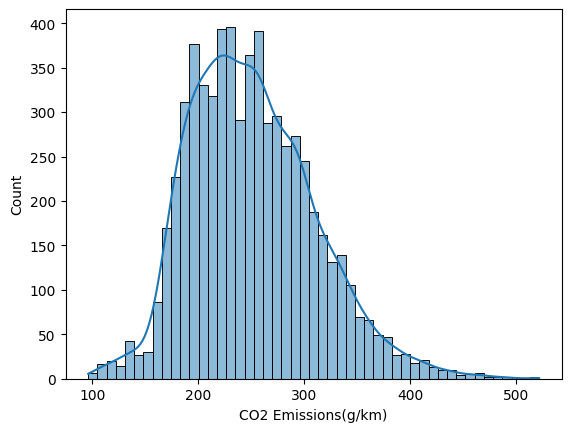

In [79]:

sns.histplot(data=df, x='CO2 Emissions(g/km)', kde=True)

El pico (la moda) se encuentra en aproximadamente los 220 y 250 g/km, consistente con el valor de la mediana (246 g/km) y la media (251,16 g/km).

La distribución de los datos presenta un ligero sesgo a la derecha, confirmando que la media es ligeramente mayor que mediana.

La mayoría de los vehículos tienden a emitir CO2 alrededor del rango de 200 a 300 g/km, con el punto de mayor concentración cercano a las 240-250 g/km.

La distribución se extiende aproximadamente desde los 100 g/km hasta un poco más de 500 g/km. Aunque la mayoría de los datos se agrupan alrededor del pico, la presencia de una cola derecha extendida indica que hay una cantidad notable de vehículos con emisiones significativamente más altas que el promedio.

Si bien no hay "saltos" drásticos que sugieran valores atípicos extremos aislados (outliers), la cola derecha sí indica que un subconjunto de vehículos emite una cantidad considerablemente mayor de CO2 que el grueso de la flota. Estos son los vehículos que "tiran" la media hacia arriba.

En resumen, este histograma valida y complementa las observaciones que hicimos a partir de las estadísticas descriptivas (media, mediana, desviación estándar), dándonos una imagen visual clara de la distribución de las emisiones de CO2.


***Análisis Multivariable***

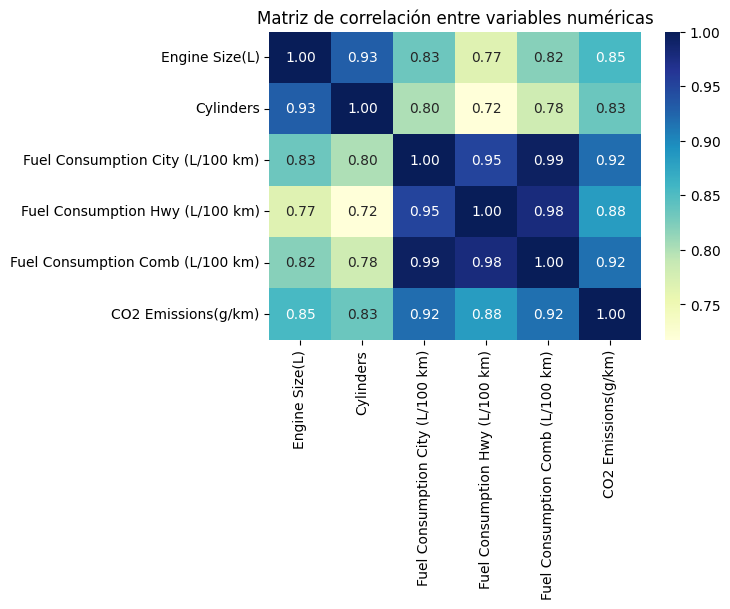

In [80]:
# Calcular la matriz de correlación para las columnas numéricas
variables = ['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)', 'CO2 Emissions(g/km)']
corr = df[variables].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap='YlGnBu', fmt=".2f")
plt.title('Matriz de correlación entre variables numéricas')
plt.show()

A partir de la matriz de correlación puedo afirmar que existe una correlación positiva fuerte entre la emisión de CO2 y el consumo de combustible en todas las situaciones planteadas. Por otra parte, el tamaño del motor y el número de cilindros también muestran una correlación positiva fuerte con las emisiones de CO2.

Todo esto confirma que el consumo de combustible y las características del motor son factores dominantes en la determinación de emisiones de CO2, revelando una interdependencia entre estas variables.

<Axes: xlabel='Fuel Consumption City (L/100 km)', ylabel='CO2 Emissions(g/km)'>

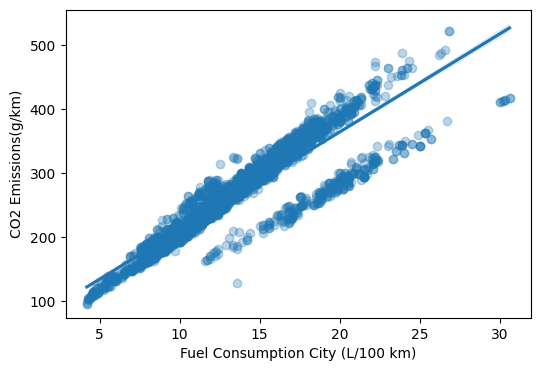

In [81]:
#Evaluar como el consumo de combustible en ciudad afecta a las emisiones de CO2 (Grafico CO2 Emissions(g/km) vs. Fuel Consumption City (L/100 km)
plt.figure(figsize=(6, 4))
sns.regplot(data=df, x='Fuel Consumption City (L/100 km)', y='CO2 Emissions(g/km)', scatter_kws={'alpha':0.3})

<Axes: xlabel='Fuel Consumption Hwy (L/100 km)', ylabel='CO2 Emissions(g/km)'>

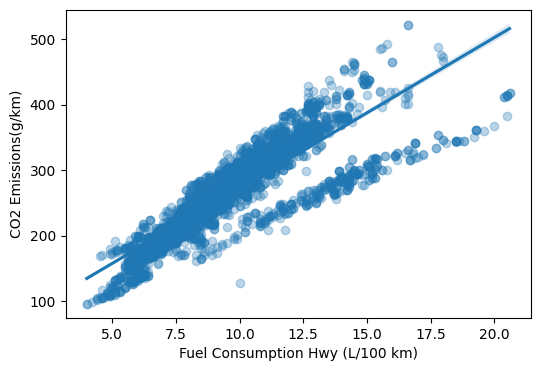

In [82]:
#Evaluar como el consumo de combustible Hwy afecta a las emisiones de CO2 (Grafico CO2 Emissions(g/km) vs. Fuel Consumption Comb (L/100 km)
plt.figure(figsize=(6, 4))
sns.regplot(data=df, x='Fuel Consumption Hwy (L/100 km)', y='CO2 Emissions(g/km)', scatter_kws={'alpha':0.3})

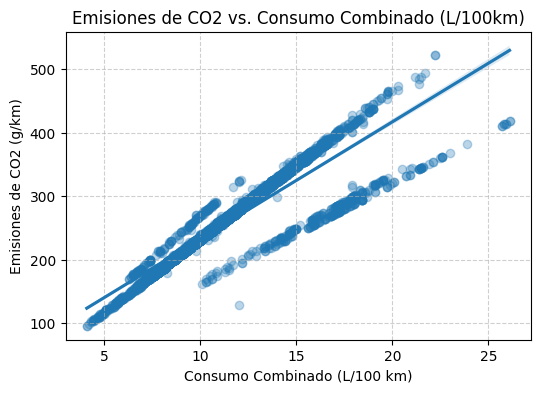

In [83]:
#Evaluar como el consumo de combustible combinado afecta a las emisiones de CO2 (Grafico CO2 Emissions(g/km) vs. Fuel Consumption Comb (L/100 km)
plt.figure(figsize=(6, 4))
sns.regplot(data=df, x='Fuel Consumption Comb (L/100 km)', y='CO2 Emissions(g/km)', scatter_kws={'alpha':0.3})
plt.title('Emisiones de CO2 vs. Consumo Combinado (L/100km)')
plt.xlabel('Consumo Combinado (L/100 km)')
plt.ylabel('Emisiones de CO2 (g/km)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

<Axes: xlabel='Engine Size(L)', ylabel='CO2 Emissions(g/km)'>

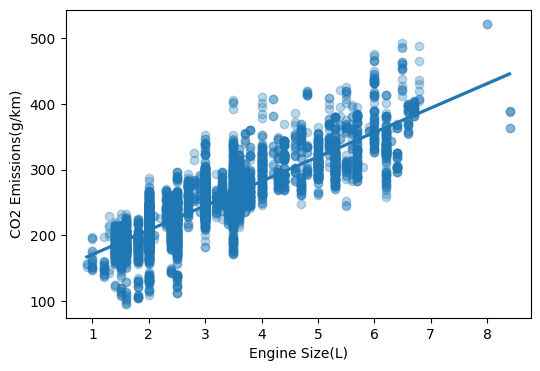

In [84]:
#Evaluar como el tamaño del motor afecta a las emisiones (CO2 Emissions(g/km) vs. Engine Size(L))
plt.figure(figsize=(6, 4))
sns.regplot(data=df, x='Engine Size(L)', y='CO2 Emissions(g/km)', scatter_kws={'alpha':0.3})

<Axes: xlabel='Cylinders', ylabel='CO2 Emissions(g/km)'>

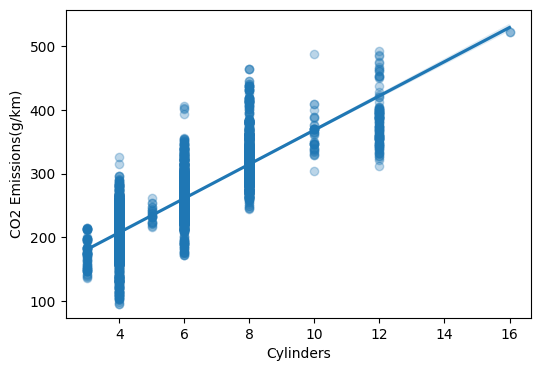

In [85]:
#Evaluar como la cantidad de cilindros afecta a las emisiones CO2 (Emissions(g/km) vs. Cylinders)
plt.figure(figsize=(6, 4))
sns.regplot(data=df, x='Cylinders', y='CO2 Emissions(g/km)', scatter_kws={'alpha':0.3})

## **Hallazgos**



Tanto las gráficas como la matriz de correlación me permiten confirmar la fuerte dependencia de las emisiones de CO2 con el consumo de combustible y las características del motor.

**Emisiones de CO2 en relación con el consumo de combustible.**

En todos los tipos de consumo (ciudad, ruta y combinado) se observa una fuerte y clara relación lineal positiva, lo que significa que a medida que un vehículo consume más combustible cada 100 km, sus emisiones de CO2 aumentan proporcionalmente. Puedo decir que esta tendencia es precisa debido a que los datos se encuentran concentrados alrededor de las líneas de regresión.

Otra observación importante es que existe una doble banda de datos, una *banda superior*, donde los vehículos muestran mayor emisión de CO2 para un determinado consumo y, una *banda inferior*, donde las emisiones de CO2 son más bajas para el mismo consumo. Esto da indicio de que existe algún factor categórico (probablemente el tipo de combustible) que crea una diferencia fundamental en la emisión de CO2.

**Emisiones de CO2 en relación con el tamaño del motor.**

Al igual que con el consumo de combustible, se observa una clara relación lineal positiva entre el tamaño del motor y la emisión de CO2. Motores más grandes implican una mayor emisión de CO2.

Si bien, la relación es fuerte, los datos no están tan concentrados en la línea de regresión, indicando que, si bien el tamaño del motor es un factor significativo, no es el “más importante”.

**Emisiones de CO2 en relación con el número de cilindros.**

A medida que el número de cilindros aumenta, las emisiones de CO2 también tienden a aumentar.

La emisión de CO2 tiende a ser más dispersa a medida que aumenta el número de cilindros. Esto podría sugerir que, si bien más cilindros generalmente significan más emisiones, en los motores más grandes y complejos, otros factores como la tecnología específica del motor o la clase del vehículo pueden tener un impacto diferenciador en las emisiones.

**En resumen**

El análisis estadístico y visual realizado sobre el conjunto de datos permitió comprender con mayor profundidad las relaciones entre las variables técnicas de los vehículos, su consumo de combustible y las emisiones de CO2.

El consumo combinado resume el comportamiento general del vehículo y se asocia de forma directa con las emisiones de CO2, con baja dispersión y alta consistencia, lo que me demuestra que lo convierte como un buen predictor individual.

También se identificó una relación entre el tamaño del motor y la cantidad de cilindros con las emisiones, aunque con mayor variabilidad. Estas variables resultan relevantes como factores técnicos complementarios, ya que aportan información adicional sobre el rendimiento del vehículo.


# **Definición de Problema y Modelo de Machine Learning**



El objetivo de esta investigación es poder predecir las emisiones de CO2 (en g/km) a partir de las características técnicas y de consumo de los vehículos. Para ello, aplicaré un enfoque de **aprendizaje supervisado**, utilizando un modelo de **regresión lineal**, debido a que la variable objetivo emisiones de CO2 es numérica y continua.

In [86]:
# Importo las bibliotecas necesarias para el modelo de ML
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

## *Definición de variables predictoras y la variable objetivo (features y target)*

Se define como variable objetivo la emisión de CO2. Como variables predictorias numéricas se elijen el consumo de combustible combinado, el tamaño del motor y el número de cilindros. Además, se incluye una variables categórica con potencial explicativo, el tipo de combustible.

In [87]:

# Defino variable objetivo (target)
target = 'CO2 Emissions(g/km)'

# Defino variables predictoras (features)
features = ['Fuel Consumption Comb (L/100 km)', 'Engine Size(L)', 'Cylinders','Fuel Type' ]

# Para modelar creo un nuevo DataFrame que contenga sólo las columnas que voy a usar
df_modelo = df[features + [target]].copy()
df_modelo

,Fuel Consumption Comb (L/100 km),Engine Size(L),Cylinders,Fuel Type,CO2 Emissions(g/km)
0,8.5,2.0,4,Z,196
1,9.6,2.4,4,Z,221
2,5.9,1.5,4,Z,136
3,11.1,3.5,6,Z,255
4,10.6,3.5,6,Z,244
...,...,...,...,...,...
7380,9.4,2.0,4,Z,219
7381,9.9,2.0,4,Z,232
7382,10.3,2.0,4,Z,240
7383,9.9,2.0,4,Z,232


In [88]:
# Codificación de la variable categórica
df_modelo_limpio = pd.get_dummies(df_modelo, columns=['Fuel Type'], drop_first=True)


In [89]:
df_modelo_limpio.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6282 entries, 0 to 7384
Data columns (total 8 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Fuel Consumption Comb (L/100 km)  6282 non-null   float64
 1   Engine Size(L)                    6282 non-null   float64
 2   Cylinders                         6282 non-null   int64  
 3   CO2 Emissions(g/km)               6282 non-null   int64  
 4   Fuel Type_E                       6282 non-null   bool   
 5   Fuel Type_N                       6282 non-null   bool   
 6   Fuel Type_X                       6282 non-null   bool   
 7   Fuel Type_Z                       6282 non-null   bool   
dtypes: bool(4), float64(2), int64(2)
memory usage: 269.9 KB


In [90]:
# Convertir columnas booleanas a enteros (0/1)
df_modelo_limpio = df_modelo_limpio.astype(int)

In [91]:
# Verifico que realizó el cambio
df_modelo_limpio.info()


<class 'pandas.core.frame.DataFrame'>
Index: 6282 entries, 0 to 7384
Data columns (total 8 columns):
 #   Column                            Non-Null Count  Dtype
---  ------                            --------------  -----
 0   Fuel Consumption Comb (L/100 km)  6282 non-null   int64
 1   Engine Size(L)                    6282 non-null   int64
 2   Cylinders                         6282 non-null   int64
 3   CO2 Emissions(g/km)               6282 non-null   int64
 4   Fuel Type_E                       6282 non-null   int64
 5   Fuel Type_N                       6282 non-null   int64
 6   Fuel Type_X                       6282 non-null   int64
 7   Fuel Type_Z                       6282 non-null   int64
dtypes: int64(8)
memory usage: 441.7 KB


In [92]:
# Divido en X (features) e y (target)
X = df_modelo_limpio.drop(target, axis=1)
Y = df_modelo_limpio[target]

## *Entrenamiento e implementación del modelo*

Luego de seleccionar las características trabajar el modelo de Regresión Lineal, avanzo en implementarlo y entrenarlo.

In [93]:
# Divido los datos en conjuntos de entrenamiento y prueba, un 80% para entrenar
# el modelo y un 20% para realizar las pruebas
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [94]:
#Creo modelo de regresión lineal
modelo = LinearRegression()

In [95]:
# Entreno el modelo con los datos de entrenamiento
modelo.fit(X_train, Y_train)

LinearRegression()

In [96]:
# Predicción sobre los datos de prueba
Y_pred = modelo.predict(X_test)

## *Evaluación del modelo*

In [97]:
# Evaluo el rendimiento del modelo mediante el coeficiente de determinación
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f"MAE: {mae}")
print(f"MSE: {mse}")
print(f"R^2: {r2}")

MAE: 6.582046504529762
MSE: 79.85517287581851
R^2: 0.9778716180628091


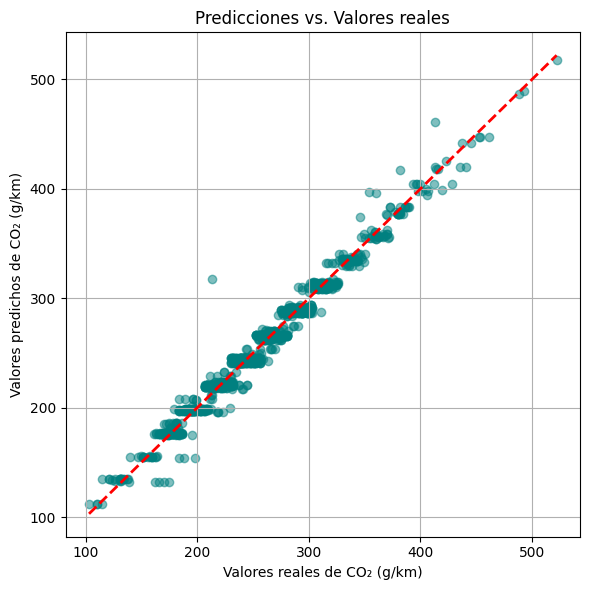

In [98]:
#graficamente
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(Y_test, Y_pred, alpha=0.5, color='teal')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red', linestyle='--', linewidth=2)
plt.xlabel('Valores reales de CO₂ (g/km)')
plt.ylabel('Valores predichos de CO₂ (g/km)')
plt.title('Predicciones vs. Valores reales')
plt.grid(True)
plt.tight_layout()
plt.show()